# HW2 Part 1: Data Cleaning and Validation

Goal: clean the `ohlc_hw` table in `data/data.db` and save the result as a new table `ohlc_hw_cleaned`.
The raw table is never changed. Run this notebook from the `Homeworks/HW2/Emil_Blaignan/` folder.

In [1]:
import os
import re
import shutil
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

db_path = 'data/data.db'
price_cols = ['open', 'high', 'low', 'close']

# use the course copy of the database if there is no local working copy yet
course_db = '../../../Lectures/Lecture 4/data/data.db'
if not os.path.exists(db_path):
    os.makedirs('data', exist_ok=True)
    shutil.copy(course_db, db_path)

## 1.1 Load and inspect the data

`ts` is the date (text, YYYY-MM-DD), `adj_close` is the vendor adjusted close (splits and dividends), the rest is the usual OHLCV.
I also load the supplied `ohlc` table. I only use it as a **reference** for each ticker's dates and for the adjustment factor.

In [2]:
conn = sqlite3.connect(db_path)
raw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)
reference = pd.read_sql_query('SELECT * FROM ohlc', conn)
conn.close()

raw.info()
display(raw.describe())
print('Date range:', raw['ts'].min(), 'to', raw['ts'].max())
print('Raw ticker strings:', raw['ticker'].nunique())
display(raw.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


,open,high,low,close,adj_close,volume
count,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
std,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08
min,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09


Date range: 1962-01-02 to 2024-12-06
Raw ticker strings: 150


,ts,open,high,low,close,adj_close,volume,ticker
0,1975-04-14,5.4300,5.4800,5.3600,5.4400,1.640000,446392,CAT
1,1978-04-05,4.8400,4.8900,4.8100,4.8800,0.656990,355200,CVX
2,2018-05-25,124.5400,124.7600,121.2200,122.1900,92.220000,8936649,CVX
3,1995-12-07,9.9700,9.9700,9.8300,9.9400,5.880000,3954150,HD
4,1981-07-23,0.1038,0.1038,0.1038,0.1038,0.080013,34451232,AAPL


In [3]:
print(raw['ticker'].unique()[:3])


def clean_ticker(text):
    """Remove the HTML tags, strip spaces and upper-case a ticker label."""
    text = re.sub(r'<[^>]+>', '', text)
    return text.strip().upper()


ticker_map = {}
for label in raw['ticker'].unique():
    ticker_map[label] = clean_ticker(label)

# audit table: original label, clean ticker, number of rows
ticker_audit = raw.groupby('ticker').size().reset_index(name='rows')
ticker_audit = ticker_audit.rename(columns={'ticker': 'raw_ticker'})
ticker_audit['ticker'] = ticker_audit['raw_ticker'].map(ticker_map)

df = raw.copy()
df['ticker'] = df['ticker'].map(ticker_map)
print('Raw labels:', raw['ticker'].nunique(), '-> tickers:', df['ticker'].nunique())
print(sorted(df['ticker'].unique()))

['CAT' 'CVX' 'HD']
Raw labels: 150 -> tickers: 30


['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


In [4]:
rows_raw = len(df)
n_exact_duplicates = df.duplicated().sum()
df = df.drop_duplicates()
n_conflicts = df.duplicated(['ticker', 'ts'], keep=False).sum()

print('Rows:', rows_raw)
print('Exact duplicates removed:', n_exact_duplicates)
print('Conflicting (ticker, ts) keys:', n_conflicts)

df = df.sort_values(['ticker', 'ts']).reset_index(drop=True)
rows_after_dedup = len(df)
print('Rows after removing duplicates:', rows_after_dedup)

Rows: 397711
Exact duplicates removed: 29460
Conflicting (ticker, ts) keys: 0


Rows after removing duplicates: 368251


## 1.2 Detect data quality issues

I write one small function per check and collect everything in the **Data Quality Report**
(`ticker | issue_type | issue_date | description | severity`). One row can show up several times.

**Severity**
- **high**: impossible or unusable values (missing/non-positive prices, open or close outside the high/low range, adj_close that disagrees with the reference table)
- **medium**: needs a decision (missing adj_close or volume, missing dates, returns more than 3 std from the mean)
- **low**: only a warning (zero volume can mean stale data, but it can also be real)

**Calendar assumption:** for each ticker, the dates in the supplied `ohlc` table are the reference calendar
(weekdays alone would include exchange holidays).

In [5]:
# Severity: high = impossible or unusable values (missing/non-positive prices, open or close outside high/low,
# adj_close different from the ohlc table); medium = needs a decision (missing adj_close or volume, missing dates,
# returns more than 3 std from the mean); low = only a warning (zero volume can be stale data but can also be real).
# Calendar: for each ticker, the dates in the ohlc table are the reference calendar.
report_columns = ['ticker', 'issue_type', 'issue_date', 'description', 'severity']


def make_issue_rows(frame, mask, issue_type, description, severity):
    """Turn a True/False mask into rows of the data quality report."""
    rows = frame.loc[mask, ['ticker', 'ts']].copy()
    rows = rows.rename(columns={'ts': 'issue_date'})
    rows['issue_type'] = issue_type
    rows['description'] = description
    rows['severity'] = severity
    return rows[report_columns]


def find_missing_dates(frame, reference):
    """Dates that are in the reference table for a ticker but not in the data."""
    rows = []
    for ticker in sorted(reference['ticker'].unique()):
        expected = set(reference.loc[reference['ticker'] == ticker, 'ts'])
        seen = set(frame.loc[frame['ticker'] == ticker, 'ts'])
        missing = sorted(expected - seen)
        if len(missing) > 0:
            print(f'Ticker {ticker} is missing {len(missing)} trading days between {missing[0]} and {missing[-1]}')
        for day in missing:
            rows.append({'ticker': ticker, 'issue_type': 'missing_date', 'issue_date': day,
                         'description': 'date is in the reference calendar but not in the data',
                         'severity': 'medium'})
    return pd.DataFrame(rows, columns=report_columns)


def find_return_outliers(frame):
    """Daily returns of close, and a mask for |return - mean| > 3 * std within each ticker.

    The frame must be sorted by ticker and ts. std is the sample std (ddof=1).
    A zero or undefined std never flags anything.
    """
    returns = frame.groupby('ticker')['close'].pct_change(fill_method=None)
    mean = returns.groupby(frame['ticker']).transform('mean')
    std = returns.groupby(frame['ticker']).transform('std')
    mask = ((returns - mean).abs() > 3 * std) & (std > 0)
    return returns, mask


def build_quality_report(frame, reference):
    """Run all the checks and return one DataFrame with one row per issue."""
    frame = frame.sort_values(['ticker', 'ts']).reset_index(drop=True)
    parts = []

    # missing values
    for col in price_cols + ['adj_close', 'volume']:
        severity = 'high'
        if col in ['adj_close', 'volume']:
            severity = 'medium'
        parts.append(make_issue_rows(frame, frame[col].isna(), 'missing_' + col, col + ' is missing', severity))

    # missing dates
    parts.append(find_missing_dates(frame, reference))

    # non-positive or non-finite prices
    for col in price_cols + ['adj_close']:
        bad = (frame[col] <= 0) | np.isinf(frame[col])
        parts.append(make_issue_rows(frame, bad, 'nonpositive_or_nonfinite_price',
                                     col + ' is not a positive finite number', 'high'))

    # impossible relationships: low <= open <= high and low <= close <= high
    open_bad = (frame['open'] > frame['high']) | (frame['open'] < frame['low'])
    close_bad = (frame['close'] > frame['high']) | (frame['close'] < frame['low'])
    parts.append(make_issue_rows(frame, open_bad, 'open_outside_high_low', 'open is not between low and high', 'high'))
    parts.append(make_issue_rows(frame, close_bad, 'close_outside_high_low', 'close is not between low and high', 'high'))

    # volume
    parts.append(make_issue_rows(frame, frame['volume'] < 0, 'negative_volume', 'volume is negative', 'high'))
    parts.append(make_issue_rows(frame, frame['volume'] == 0, 'zero_volume', 'zero volume (maybe stale data)', 'low'))

    # extreme returns
    returns, outlier_mask = find_return_outliers(frame)
    text = 'return of ' + (returns * 100).round(2).astype(str) + '% is more than 3 std from the mean'
    parts.append(make_issue_rows(frame, outlier_mask, 'extreme_return', text[outlier_mask], 'medium'))

    # adj_close that is different from the reference table
    ref_adj = reference[['ticker', 'ts', 'adj_close']].rename(columns={'adj_close': 'ref_adj_close'})
    merged = frame[['ticker', 'ts', 'adj_close']].merge(ref_adj, on=['ticker', 'ts'], how='left')
    mismatch = merged['adj_close'].notna() & ~np.isclose(merged['adj_close'], merged['ref_adj_close'])
    parts.append(make_issue_rows(frame, mismatch, 'adj_close_mismatch',
                                 'adj_close is different from the adj_close in the ohlc table', 'high'))

    report = pd.concat(parts, ignore_index=True)
    return report.sort_values(['ticker', 'issue_date', 'issue_type']).reset_index(drop=True)

In [6]:
toy_reference = pd.DataFrame({'ticker': ['AAA'] * 4,
                              'ts': ['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05']})
toy_data = toy_reference.drop(index=2)   # remove 2024-01-04
display(find_missing_dates(toy_data, toy_reference))

Ticker AAA is missing 1 trading days between 2024-01-04 and 2024-01-04


,ticker,issue_type,issue_date,description,severity
0,AAA,missing_date,2024-01-04,date is in the reference calendar but not in t...,medium


In [7]:
report_before = build_quality_report(df, reference)
print('Total issue rows:', len(report_before))
display(report_before.groupby(['issue_type', 'severity']).size().reset_index(name='rows'))
display(report_before.head(10))

Total issue rows: 33932


,issue_type,severity,rows
0,adj_close_mismatch,high,10417
1,extreme_return,medium,5056
2,missing_adj_close,medium,18374
3,nonpositive_or_nonfinite_price,high,5
4,open_outside_high_low,high,5
5,zero_volume,low,75


,ticker,issue_type,issue_date,description,severity
0,AAPL,extreme_return,1980-12-26,return of 9.23% is more than 3 std from the mean,medium
1,AAPL,missing_adj_close,1981-01-08,adj_close is missing,medium
2,AAPL,missing_adj_close,1981-01-13,adj_close is missing,medium
3,AAPL,adj_close_mismatch,1981-02-03,adj_close is different from the adj_close in t...,high
4,AAPL,missing_adj_close,1981-02-12,adj_close is missing,medium
5,AAPL,extreme_return,1981-04-02,return of 8.77% is more than 3 std from the mean,medium
6,AAPL,missing_adj_close,1981-04-16,adj_close is missing,medium
7,AAPL,adj_close_mismatch,1981-04-28,adj_close is different from the adj_close in t...,high
8,AAPL,adj_close_mismatch,1981-05-08,adj_close is different from the adj_close in t...,high
9,AAPL,missing_adj_close,1981-05-19,adj_close is missing,medium


What I see:
- Only `adj_close` has missing values (18,374). Raw prices and volume are complete.
- `adj_close_mismatch`: 10,417 values are different from the `ohlc` table. They are 4x to 24x too large (bigger than the close), so they are corrupted, not just missing.
- 5 rows have `open = 0` (so open is also outside high/low).
- 75 days with zero volume.
- 5,056 returns are more than 3 std from the mean. I need to look at those.
- No missing dates: `ohlc_hw` has every date that `ohlc` has. A check can correctly find nothing.

### Looking at the extreme returns

First question: is the raw price data different from `ohlc`? If it is identical, the prices in `ohlc_hw` were not corrupted by this table.

In [8]:
check = df.merge(reference, on=['ticker', 'ts'], suffixes=('', '_ref'))
for col in price_cols + ['volume']:
    print(col, 'rows different from ohlc:', (check[col] != check[col + '_ref']).sum())

open rows different from ohlc: 0
high rows different from ohlc: 0
low rows different from ohlc: 0
close rows different from ohlc: 0
volume rows different from ohlc: 0


In [9]:
# Some extreme returns have zero volume. Looking at the days around them, the price jumps, nothing trades and the
# next day it is back to normal, so extreme return + zero volume is treated as a bad print and interpolated.
# All the other extreme returns look like real market moves and are only flagged.
returns, outlier_mask = find_return_outliers(df)
zero_volume_outliers = df[outlier_mask & (df['volume'] == 0)]
display(zero_volume_outliers)

# look at the days around each one
for i in zero_volume_outliers.index:
    display(df.loc[i - 2:i + 2, ['ticker', 'ts', 'open', 'high', 'low', 'close', 'volume']])

,ts,open,high,low,close,adj_close,volume,ticker
28586,1972-12-14,4.01,4.01,4.01,4.01,1.35,0,AXP
318332,1976-10-28,9.22,9.22,9.22,9.22,NaN,0,TRV
318873,1978-12-20,8.03,8.03,8.03,8.03,2.80,0,TRV
319538,1981-08-10,12.06,12.06,12.06,12.06,4.20,0,TRV


,ticker,ts,open,high,low,close,volume
28584,AXP,1972-12-12,4.63,4.63,4.63,4.63,672324
28585,AXP,1972-12-13,4.59,4.59,4.59,4.59,844816
28586,AXP,1972-12-14,4.01,4.01,4.01,4.01,0
28587,AXP,1972-12-15,4.60,4.60,4.60,4.60,979282
28588,AXP,1972-12-18,4.60,4.60,4.60,4.60,421049


,ticker,ts,open,high,low,close,volume
318330,TRV,1976-10-26,4.50,4.50,4.50,4.50,91200
318331,TRV,1976-10-27,4.61,4.61,4.61,4.61,230400
318332,TRV,1976-10-28,9.22,9.22,9.22,9.22,0
318333,TRV,1976-10-29,4.69,4.69,4.69,4.69,79200
318334,TRV,1976-11-01,4.66,4.66,4.66,4.66,59200


,ticker,ts,open,high,low,close,volume
318871,TRV,1978-12-18,4.02,4.02,4.02,4.02,155200
318872,TRV,1978-12-19,4.02,4.02,4.02,4.02,72000
318873,TRV,1978-12-20,8.03,8.03,8.03,8.03,0
318874,TRV,1978-12-21,4.09,4.09,4.09,4.09,105600
318875,TRV,1978-12-22,4.09,4.09,4.09,4.09,91200


,ticker,ts,open,high,low,close,volume
319536,TRV,1981-08-06,6.06,6.06,6.06,6.06,60000
319537,TRV,1981-08-07,6.03,6.03,6.03,6.03,264800
319538,TRV,1981-08-10,12.06,12.06,12.06,12.06,0
319539,TRV,1981-08-11,6.03,6.03,6.03,6.03,24800
319540,TRV,1981-08-12,6.13,6.13,6.13,6.13,267200


These 4 days (AXP 1972-12-14, TRV 1976-10-28, 1978-12-20, 1981-08-10) are bad prints: the price jumps, nothing traded,
and the next day the price is back to normal. A real move would not come straight back with zero volume.
So I treat an **extreme return together with zero volume** as a data error and fix it by interpolating between the neighbouring days.
All the other extreme returns are kept and only flagged (`return_outlier`), since they look like real market moves.
(I did not check the news for every date.)

## 1.3 Clean the data

Everything is done inside each ticker, sorted by date.
1. Drop rows where all four prices are missing (before any filling).
2. Non-positive prices become missing. Missing high/low are forward-filled. Open/close that are missing, non-positive or outside `[low, high]` take the previous close if it is inside today's range, otherwise the middle of low and high.
3. Rows that still have missing prices (for example a gap at the start of a ticker) go to the quarantine table with a reason.
4. Missing volume becomes 0 with a flag (unknown volume is not proof that nothing traded).
5. Bad prints (extreme return and zero volume): replace the prices by the average of the day before and the day after.
6. `adj_close`: if it is missing or different from the `ohlc` value, rebuild it as `close * factor`, where `factor = adj_close / close` from the same ticker and date in `ohlc`. For the bad prints, `adj_close` is the average of the neighbouring days. Rows with no factor go to quarantine.
7. Every repair sets a flag column.

In [10]:
def clean_data(frame, reference):
    """Clean the data inside each ticker. Returns (cleaned, quarantine).

    Steps: drop rows with all prices missing, fix the prices, quarantine what cannot be fixed, fix the volume,
    interpolate the bad prints, rebuild adj_close from the factor in the ohlc table.
    """
    frame = frame.sort_values(['ticker', 'ts']).reset_index(drop=True)
    quarantine_parts = []

    # 1. drop rows where all prices are missing
    all_missing = frame[price_cols].isna().all(axis=1)
    removed = frame[all_missing].copy()
    removed['reason'] = 'all prices missing'
    quarantine_parts.append(removed)
    frame = frame[~all_missing].reset_index(drop=True)

    # 2. prices: non-positive -> missing, then fill
    for col in price_cols:
        frame.loc[frame[col] <= 0, col] = np.nan
    open_bad = frame['open'].isna() | (frame['open'] > frame['high']) | (frame['open'] < frame['low'])
    close_bad = frame['close'].isna() | (frame['close'] > frame['high']) | (frame['close'] < frame['low'])
    frame['price_repaired'] = frame[price_cols].isna().any(axis=1) | open_bad | close_bad

    frame['high'] = frame.groupby('ticker')['high'].ffill()
    frame['low'] = frame.groupby('ticker')['low'].ffill()
    previous_close = frame.groupby('ticker')['close'].shift(1)
    middle = (frame['high'] + frame['low']) / 2
    previous_ok = previous_close.between(frame['low'], frame['high'])
    replacement = previous_close.where(previous_ok, middle)
    frame.loc[open_bad, 'open'] = replacement[open_bad]
    frame.loc[close_bad, 'close'] = replacement[close_bad]

    # 3. quarantine rows that are still missing prices
    still_missing = frame[price_cols].isna().any(axis=1)
    removed = frame[still_missing].copy()
    removed['reason'] = 'prices could not be repaired'
    quarantine_parts.append(removed)
    frame = frame[~still_missing].reset_index(drop=True)

    # 4. volume (zero volume is checked before the missing volume is set to 0)
    zero_volume = frame['volume'] == 0
    frame['volume_repaired'] = frame['volume'].isna()
    frame.loc[frame['volume_repaired'], 'volume'] = 0

    # 5. bad prints: extreme return and zero volume -> average of the neighbouring days
    returns, outlier_mask = find_return_outliers(frame)
    bad_print = outlier_mask & zero_volume
    frame['price_interpolated'] = bad_print
    for col in price_cols:
        before = frame.groupby('ticker')[col].shift(1)
        after = frame.groupby('ticker')[col].shift(-1)
        frame.loc[bad_print, col] = ((before + after) / 2)[bad_print]

    # 6. adj_close from the factor in the ohlc table
    trusted = reference[['ticker', 'ts', 'close', 'adj_close']].copy()
    trusted['factor'] = trusted['adj_close'] / trusted['close']
    trusted = trusted.rename(columns={'adj_close': 'ref_adj_close'})
    frame = frame.merge(trusted[['ticker', 'ts', 'ref_adj_close', 'factor']], on=['ticker', 'ts'], how='left')

    bad_adj = ~np.isclose(frame['adj_close'], frame['ref_adj_close'])   # also True when adj_close is missing
    can_fix = bad_adj & frame['factor'].notna()
    frame.loc[can_fix, 'adj_close'] = frame.loc[can_fix, 'close'] * frame.loc[can_fix, 'factor']
    frame['adj_close_repaired'] = can_fix

    before = frame.groupby('ticker')['adj_close'].shift(1)
    after = frame.groupby('ticker')['adj_close'].shift(-1)
    frame.loc[bad_print, 'adj_close'] = ((before + after) / 2)[bad_print]
    frame.loc[bad_print, 'adj_close_repaired'] = True

    no_factor = bad_adj & frame['factor'].isna()
    removed = frame[no_factor].copy()
    removed['reason'] = 'adj_close is bad and there is no factor in ohlc'
    quarantine_parts.append(removed)
    frame = frame[~no_factor].reset_index(drop=True)

    cleaned = frame[['ts', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume',
                     'price_repaired', 'volume_repaired', 'adj_close_repaired', 'price_interpolated']].copy()
    quarantine = pd.concat(quarantine_parts, ignore_index=True)
    quarantine = quarantine[['ts', 'ticker', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'reason']]
    return cleaned, quarantine


def validate(frame):
    """Count the rows that break each rule. Everything should be 0."""
    all_prices = price_cols + ['adj_close']
    checks = {}
    checks['missing_or_nonfinite_prices'] = int((~np.isfinite(frame[all_prices])).sum().sum())
    checks['nonpositive_prices'] = int((frame[all_prices] <= 0).sum().sum())
    checks['duplicate_ticker_ts'] = int(frame.duplicated(['ticker', 'ts']).sum())
    checks['bad_volume'] = int((~np.isfinite(frame['volume']) | (frame['volume'] < 0)).sum())
    checks['open_outside_low_high'] = int(((frame['open'] > frame['high']) | (frame['open'] < frame['low'])).sum())
    checks['close_outside_low_high'] = int(((frame['close'] > frame['high']) | (frame['close'] < frame['low'])).sum())
    checks['high_below_low'] = int((frame['high'] < frame['low']).sum())
    dates = pd.to_datetime(frame['ts'], format='%Y-%m-%d', errors='coerce')
    checks['ts_not_iso_date'] = int(dates.isna().sum())
    return pd.Series(checks)

In [11]:
nan = np.nan
toy_reference = pd.DataFrame({
    'ticker': ['AAA'] * 5 + ['BBB'] * 3,
    'ts': ['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05', '2024-01-08',
           '2024-01-02', '2024-01-03', '2024-01-04'],
    'close': [10.0, 10.5, 10.8, 11.0, 11.2, 20.0, 21.0, 21.0],
    'adj_close': [5.0, 5.25, 5.4, 5.5, 5.6, 10.0, 10.5, 10.5],
})
toy_dirty = pd.DataFrame({
    'ticker': ['AAA', 'AAA', 'AAA', 'AAA', 'BBB', 'BBB', 'BBB'],
    'ts': ['2024-01-02', '2024-01-03', '2024-01-05', '2024-01-08', '2024-01-02', '2024-01-03', '2024-01-04'],
    'open': [10.0, 10.0, 0.0, nan, 20.0, 20.0, 21.0],
    'high': [11.0, 11.0, 12.0, nan, nan, 22.0, 22.0],
    'low': [9.0, 9.0, 10.0, nan, nan, 19.0, 20.0],
    'close': [10.0, 10.5, 11.0, nan, 20.0, 25.0, 21.0],
    'adj_close': [5.0, 5.25, nan, nan, 10.0, 12.5, 99.0],
    'volume': [1000, nan, 1000, 500, 100, 100, 100],
})
# Problems: AAA 01-03 volume missing | AAA 01-05 open is 0 and adj_close missing | AAA 01-08 all prices missing
# BBB 01-02 high and low missing at the start (cannot fill) | BBB 01-03 close above high | BBB 01-04 adj_close is wrong
# (and AAA is also missing 2024-01-04)

display(build_quality_report(toy_dirty, toy_reference)[['ticker', 'issue_type', 'issue_date', 'severity']])

toy_clean, toy_quarantine = clean_data(toy_dirty, toy_reference)
display(toy_clean)
display(toy_quarantine)

toy_indexed = toy_clean.set_index(['ticker', 'ts'])
assert len(toy_clean) == 5 and len(toy_quarantine) == 2
assert toy_indexed.loc[('AAA', '2024-01-05'), 'open'] == 10.5
assert toy_indexed.loc[('AAA', '2024-01-05'), 'adj_close'] == 5.5
assert toy_indexed.loc[('AAA', '2024-01-03'), 'volume'] == 0
assert toy_indexed.loc[('BBB', '2024-01-03'), 'close'] == 20.0
assert toy_indexed.loc[('BBB', '2024-01-04'), 'adj_close'] == 10.5
assert (validate(toy_clean) == 0).all()
print('The small example works.')

Ticker AAA is missing 1 trading days between 2024-01-04 and 2024-01-04


,ticker,issue_type,issue_date,severity
0,AAA,missing_volume,2024-01-03,medium
1,AAA,missing_date,2024-01-04,medium
2,AAA,missing_adj_close,2024-01-05,medium
3,AAA,nonpositive_or_nonfinite_price,2024-01-05,high
4,AAA,open_outside_high_low,2024-01-05,high
5,AAA,missing_adj_close,2024-01-08,medium
6,AAA,missing_close,2024-01-08,high
7,AAA,missing_high,2024-01-08,high
8,AAA,missing_low,2024-01-08,high
9,AAA,missing_open,2024-01-08,high


,ts,ticker,open,high,low,close,adj_close,volume,price_repaired,volume_repaired,adj_close_repaired,price_interpolated
0,2024-01-02,AAA,10.0,11.0,9.0,10.0,5.00,1000.0,False,False,False,False
1,2024-01-03,AAA,10.0,11.0,9.0,10.5,5.25,0.0,False,True,False,False
2,2024-01-05,AAA,10.5,12.0,10.0,11.0,5.50,1000.0,True,False,True,False
3,2024-01-03,BBB,20.0,22.0,19.0,20.0,10.00,100.0,True,False,True,False
4,2024-01-04,BBB,21.0,22.0,20.0,21.0,10.50,100.0,False,False,True,False


,ts,ticker,open,high,low,close,adj_close,volume,reason
0,2024-01-08,AAA,NaN,NaN,NaN,NaN,NaN,500.0,all prices missing
1,2024-01-02,BBB,20.0,NaN,NaN,20.0,10.0,100.0,prices could not be repaired


The small example works.


In [12]:
cleaned, quarantine = clean_data(df, reference)

# keep the extreme returns but flag them
returns, outlier_mask = find_return_outliers(cleaned)
cleaned['return_outlier'] = outlier_mask

print('Rows kept:', len(cleaned))
print('Rows in quarantine:', len(quarantine))
display(cleaned[['price_repaired', 'volume_repaired', 'adj_close_repaired',
                 'price_interpolated', 'return_outlier']].sum())

# the bad prints before and after
for ticker, day in [('AXP', '1972-12-14'), ('TRV', '1976-10-28')]:
    i = df.index[(df['ticker'] == ticker) & (df['ts'] == day)][0]
    j = cleaned.index[(cleaned['ticker'] == ticker) & (cleaned['ts'] == day)][0]
    print('BEFORE', ticker)
    display(df.loc[i - 1:i + 1, ['ticker', 'ts', 'close', 'adj_close', 'volume']])
    print('AFTER', ticker)
    display(cleaned.loc[j - 1:j + 1, ['ticker', 'ts', 'close', 'adj_close', 'volume', 'price_interpolated']])

Rows kept: 368251
Rows in quarantine: 0


price_repaired            5
volume_repaired           0
adj_close_repaired    28794
price_interpolated        4
return_outlier         5173
dtype: int64

BEFORE AXP


,ticker,ts,close,adj_close,volume
28585,AXP,1972-12-13,4.59,NaN,844816
28586,AXP,1972-12-14,4.01,1.35,0
28587,AXP,1972-12-15,4.60,1.56,979282


AFTER AXP


,ticker,ts,close,adj_close,volume,price_interpolated
28585,AXP,1972-12-13,4.590,1.550,844816,False
28586,AXP,1972-12-14,4.595,1.555,0,True
28587,AXP,1972-12-15,4.600,1.560,979282,False


BEFORE TRV


,ticker,ts,close,adj_close,volume
318331,TRV,1976-10-27,4.61,13.88325,230400
318332,TRV,1976-10-28,9.22,NaN,0
318333,TRV,1976-10-29,4.69,0.99707,79200


AFTER TRV


,ticker,ts,close,adj_close,volume,price_interpolated
318331,TRV,1976-10-27,4.61,0.980460,230400,False
318332,TRV,1976-10-28,4.65,0.988765,0,True
318333,TRV,1976-10-29,4.69,0.997070,79200,False


## 1.4 Validation

Every count after cleaning must be 0. The table also shows the counts before cleaning (after fixing tickers and removing exact duplicates).

In [13]:
validation = pd.DataFrame({'before_cleaning': validate(df), 'after_cleaning': validate(cleaned)})
display(validation)
assert (validation['after_cleaning'] == 0).all()

# run the quality report again on the cleaned data
report_after = build_quality_report(cleaned, reference)
display(report_after.groupby(['issue_type', 'severity']).size().reset_index(name='rows'))

# the only high severity rows left are the 4 bad prints: their adj_close is different from ohlc on purpose,
# because the value in ohlc is also wrong there
high_left = report_after[report_after['severity'] == 'high']
display(high_left)
assert (high_left['issue_type'] == 'adj_close_mismatch').all()
assert len(high_left) == cleaned['price_interpolated'].sum()

,before_cleaning,after_cleaning
missing_or_nonfinite_prices,18374,0
nonpositive_prices,5,0
duplicate_ticker_ts,0,0
bad_volume,0,0
open_outside_low_high,5,0
close_outside_low_high,0,0
high_below_low,0,0
ts_not_iso_date,0,0


,issue_type,severity,rows
0,adj_close_mismatch,high,4
1,extreme_return,medium,5173
2,zero_volume,low,75


,ticker,issue_type,issue_date,description,severity
463,AXP,adj_close_mismatch,1972-12-14,adj_close is different from the adj_close in t...,high
4477,TRV,adj_close_mismatch,1976-10-28,adj_close is different from the adj_close in t...,high
4480,TRV,adj_close_mismatch,1978-12-20,adj_close is different from the adj_close in t...,high
4482,TRV,adj_close_mismatch,1981-08-10,adj_close is different from the adj_close in t...,high


In [14]:
accounting = pd.DataFrame({'rows': [rows_raw, n_exact_duplicates, rows_after_dedup, len(quarantine), len(cleaned)]},
                          index=['ohlc_hw rows', 'exact duplicates removed', 'unique rows',
                                 'quarantined', 'kept in ohlc_hw_cleaned'])
display(accounting)
assert rows_after_dedup - len(quarantine) == len(cleaned)

# before / after statistics
for col in ['open', 'close', 'adj_close', 'volume']:
    print(col)
    display(pd.DataFrame({'before': df[col].describe(), 'after': cleaned[col].describe()}).round(3))

,rows
ohlc_hw rows,397711
exact duplicates removed,29460
unique rows,368251
quarantined,0
kept in ohlc_hw_cleaned,368251


open


,before,after
count,368251.000,368251.000
mean,46.309,46.309
std,67.143,67.143
min,0.000,0.005
25%,4.210,4.210
50%,19.890,19.890
75%,57.560,57.560
max,604.260,604.260


close


,before,after
count,368251.000,368251.000
mean,46.317,46.317
std,67.155,67.155
min,0.005,0.005
25%,4.210,4.210
50%,19.900,19.900
75%,57.570,57.570
max,605.400,605.400


adj_close


,before,after
count,349877.000,368251.000
mean,51.712,37.274
std,195.002,63.588
min,0.003,0.003
25%,1.396,1.310
50%,11.980,11.460
75%,43.790,41.570
max,10442.511,605.400


volume


,before,after
count,3.682510e+05,3.682510e+05
mean,3.095142e+07,3.095142e+07
std,1.266145e+08,1.266145e+08
min,0.000000e+00,0.000000e+00
25%,1.731400e+06,1.731400e+06
50%,4.649600e+06,4.649600e+06
75%,1.102151e+07,1.102151e+07
max,9.276606e+09,9.276606e+09


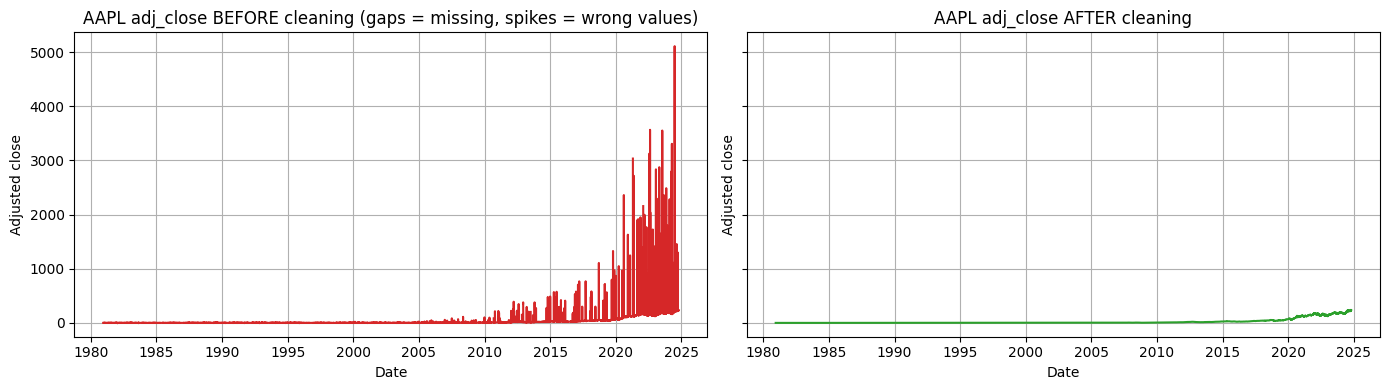

In [15]:
# AAPL adjusted close before and after
before_aapl = df[df['ticker'] == 'AAPL'].copy()
after_aapl = cleaned[cleaned['ticker'] == 'AAPL'].copy()
before_aapl['ts'] = pd.to_datetime(before_aapl['ts'])
after_aapl['ts'] = pd.to_datetime(after_aapl['ts'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].plot(before_aapl['ts'], before_aapl['adj_close'], color='tab:red')
axes[0].set_title('AAPL adj_close BEFORE cleaning (gaps = missing, spikes = wrong values)')
axes[1].plot(after_aapl['ts'], after_aapl['adj_close'], color='tab:green')
axes[1].set_title('AAPL adj_close AFTER cleaning')
for ax in axes:
    ax.set_xlabel('Date')
    ax.set_ylabel('Adjusted close')
    ax.grid(True)
plt.tight_layout()
plt.show()

In [16]:
conn = sqlite3.connect(db_path)
cleaned.to_sql('ohlc_hw_cleaned', conn, if_exists='replace', index=False)
quarantine.to_sql('ohlc_hw_quarantine', conn, if_exists='replace', index=False)
ticker_audit.to_sql('ohlc_hw_ticker_audit', conn, if_exists='replace', index=False)

# read it back
saved = pd.read_sql_query('SELECT * FROM ohlc_hw_cleaned', conn)
raw_rows_now = pd.read_sql_query('SELECT COUNT(*) AS n FROM ohlc_hw', conn)['n'].iloc[0]
conn.close()

print('Saved rows:', len(saved), '| rows still in ohlc_hw:', raw_rows_now)
assert len(saved) == len(cleaned)
assert raw_rows_now == rows_raw
assert (validate(saved) == 0).all()
display(saved.head())

Saved rows: 368251 | rows still in ohlc_hw: 397711


,ts,ticker,open,high,low,close,adj_close,volume,price_repaired,volume_repaired,adj_close_repaired,price_interpolated,return_outlier
0,1980-12-12,AAPL,0.12835,0.12835,0.12835,0.12835,0.098941,469034068,0,0,0,0,0
1,1980-12-15,AAPL,0.12165,0.12165,0.12165,0.12165,0.093779,175884971,0,0,0,0,0
2,1980-12-16,AAPL,0.11272,0.11272,0.11272,0.11272,0.086896,105728103,0,0,0,0,0
3,1980-12-17,AAPL,0.11551,0.11551,0.11551,0.11551,0.089046,86441684,0,0,0,0,0
4,1980-12-18,AAPL,0.11886,0.11886,0.11886,0.11886,0.091627,73449671,0,0,0,0,0
